# Interview Camera Watcher
Watches a candidate's webcam / video and turns it into **observations -> events -> 5 s rolling features -> risk score**.

```
camera/video -> OpenCV frames
    |-- face + iris (MediaPipe, ~10 fps)  -> face_present, gaze
    '-- person + objects (YOLO+ByteTrack, ~3 fps) -> person_count, phone/laptop/...
        -> per-frame Obs -> persistence rules -> events
        -> 5 s rolling window, every 1 s -> feature dict (flat, versioned) -> risk score
        -> evidence (frames, clip, JSON)
```
Scope: this notebook is the **camera-watching part only**. Plug your own XGBoost in through `risk_fn` (see the last cells);
until then a clearly-labelled *rule-based* risk score is used. It is **not** a calibrated probability of cheating.
All thresholds live in `config.yaml`.

In [1]:
# --- 1. imports (run `pip install -r requirements.txt` first; use ONE OpenCV wheel only) ---
import json, logging, math, time, uuid
from collections import deque
from dataclasses import dataclass, field, asdict
from datetime import datetime, timedelta
from pathlib import Path

import cv2
import numpy as np
import yaml
import mediapipe as mp
from IPython.display import display, clear_output, Image as IPyImage
from ultralytics import YOLO

In [2]:
# --- 2. config + logging ---
def find_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "config.yaml").exists():
            return p
    raise FileNotFoundError("config.yaml not found - open this notebook from the interview/ folder")

ROOT = find_root()
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
FEATURE_SCHEMA_VERSION = "1.0"

class JsonFormatter(logging.Formatter):
    def format(self, record):
        payload = {"ts": datetime.now().isoformat(timespec="milliseconds"),
                   "level": record.levelname, "msg": record.getMessage()}
        payload.update(getattr(record, "data", {}))
        return json.dumps(payload, default=str)

log = logging.getLogger("interview")
log.setLevel(logging.INFO)
log.propagate = False
if not log.handlers:
    _console = logging.StreamHandler()
    _console.setLevel(logging.WARNING)           # keep the console quiet; details go to the session log file
    _console.setFormatter(logging.Formatter("[%(levelname)s] %(message)s"))
    log.addHandler(_console)

def attach_session_log(path: Path):
    for h in list(log.handlers):
        if isinstance(h, logging.FileHandler):
            h.close(); log.removeHandler(h)
    fh = logging.FileHandler(path, encoding="utf-8")
    fh.setFormatter(JsonFormatter())
    log.addHandler(fh)

def fmt_t(t: float) -> str:
    """seconds -> HH:MM:SS.mmm"""
    t = max(0.0, float(t))
    return f"{int(t // 3600):02d}:{int(t % 3600 // 60):02d}:{int(t % 60):02d}.{int(round((t % 1) * 1000)) % 1000:03d}"

print("root:", ROOT, "| opencv", cv2.__version__)

root: d:\claude\interview | opencv 4.11.0


In [3]:
# --- 3. data types ---
@dataclass
class FaceObs:
    count: int = 0
    present: bool = False
    bbox: tuple | None = None        # x1,y1,x2,y2 in pixels (largest face)
    cx: float | None = None          # normalised face centre
    cy: float | None = None
    metrics: dict | None = None      # raw iris/head ratios for the largest face
    iris_px: list = field(default_factory=list)

@dataclass
class Det:
    group: str                       # person | phone | laptop | tablet | other
    name: str                        # raw class name
    conf: float
    bbox: tuple
    track_id: int | None = None

@dataclass
class Obs:
    """One observation per processed frame (detector results are carried forward between detector runs)."""
    t: float
    face_present: bool
    face_count: int
    face_x: float | None
    face_y: float | None
    gaze: str
    gaze_x: float
    gaze_y: float
    gaze_valid: bool
    person_count: int
    groups: dict                     # group -> best confirmed confidence (only present groups)
    det_confs: tuple = ()

In [4]:
# --- 4. gaze estimation (coarse, landmark-ratio based) ---
# MediaPipe FaceMesh with refine_landmarks=True gives iris centres 468 (subject's right eye) and 473 (left eye).
# Directions are as seen in the CAMERA IMAGE (LEFT = image-left).
def _proj(p, a, b) -> float:
    """Position of p along the axis a->b (0 at a, 1 at b)."""
    ab = b - a
    return float(np.dot(p - a, ab) / (np.dot(ab, ab) + 1e-9))

def raw_gaze_metrics(pts: np.ndarray) -> dict:
    """pts: (478,2) normalised landmarks -> iris & head-pose ratios (0.5 ~ centred)."""
    return {
        "iris_x": (_proj(pts[468], pts[33], pts[133]) + _proj(pts[473], pts[362], pts[263])) / 2,
        "iris_y": (_proj(pts[468], pts[159], pts[145]) + _proj(pts[473], pts[386], pts[374])) / 2,
        "head_x": _proj(pts[1], pts[234], pts[454]),     # nose between cheeks  (yaw)
        "head_y": _proj(pts[1], pts[10], pts[152]),      # nose between forehead and chin (pitch)
    }

def classify_gaze(m: dict, neutral: dict, thr: dict):
    """Deviation from the personal baseline, normalised so |value| >= 1 means 'beyond threshold'.
    Iris offset and head turn are both considered; the stronger one wins."""
    hx = [(m["iris_x"] - neutral["iris_x"]) / thr["iris_x"], (m["head_x"] - neutral["head_x"]) / thr["head_x"]]
    vy = [(m["iris_y"] - neutral["iris_y"]) / thr["iris_y"], (m["head_y"] - neutral["head_y"]) / thr["head_y"]]
    gx = max(hx, key=abs)
    gy = max(vy, key=abs)
    if max(abs(gx), abs(gy)) < 1.0:
        direction = "CENTER"
    elif abs(gx) >= abs(gy):
        direction = "RIGHT" if gx > 0 else "LEFT"
    else:
        direction = "DOWN" if gy > 0 else "UP"
    return direction, float(np.clip(gx, -3, 3)), float(np.clip(gy, -3, 3))

class GazeEstimator:
    """Learns the candidate's 'looking at the screen' baseline during the first `calibration_s` seconds of face time."""
    KEYS = ("iris_x", "iris_y", "head_x", "head_y")

    def __init__(self, gcfg: dict):
        self.thr = {k: gcfg[f"{k}_thresh"] for k in self.KEYS}
        self.calibration_s = float(gcfg["calibration_s"])
        self.neutral = dict(gcfg["default_neutral"])
        self.calibrated = self.calibration_s <= 0
        self._samples, self._t0 = [], None

    def update(self, metrics: dict | None, t: float):
        """-> (direction, gx, gy, valid)"""
        if metrics is None:
            return "CENTER", 0.0, 0.0, False
        if not self.calibrated:
            self._t0 = t if self._t0 is None else self._t0
            self._samples.append([metrics[k] for k in self.KEYS])
            if t - self._t0 >= self.calibration_s and len(self._samples) >= 5:
                med = np.median(np.array(self._samples), axis=0)
                self.neutral = dict(zip(self.KEYS, map(float, med)))
                self.calibrated = True
                log.info("gaze calibrated", extra={"data": {"neutral": self.neutral}})
            return "CENTER", 0.0, 0.0, False
        d, gx, gy = classify_gaze(metrics, self.neutral, self.thr)
        return d, gx, gy, True

In [5]:
# --- 5. detectors: MediaPipe (face/iris) + YOLO (person/objects). Models load ONCE; failures degrade, never crash. ---
class Detectors:
    def __init__(self, cfg: dict):
        self.cfg = cfg
        self.face_mesh = None
        self.yolo = None
        self.use_tracking = True
        self.group_ids: dict[int, tuple[str, str]] = {}      # class id -> (group, name)
        self._yolo_fail = 0
        self.last_face_ms = 0.0
        self.last_yolo_ms = 0.0
        self._load_face()
        self._load_yolo()

    @property
    def face_ok(self): return self.face_mesh is not None
    @property
    def yolo_ok(self): return self.yolo is not None

    def _load_face(self):
        f = self.cfg["face"]
        try:
            self.face_mesh = mp.solutions.face_mesh.FaceMesh(
                static_image_mode=False, max_num_faces=f["max_faces"], refine_landmarks=True,
                min_detection_confidence=f["min_detection_confidence"],
                min_tracking_confidence=f["min_tracking_confidence"])
        except Exception as e:
            log.error(f"MediaPipe FaceMesh failed to load: {e}. Face/gaze signals disabled.")

    def _load_yolo(self):
        y = self.cfg["yolo"]
        try:
            weights = ROOT / "models" / y["model"]
            weights.parent.mkdir(exist_ok=True)
            if not weights.exists():
                from ultralytics.utils.downloads import attempt_download_asset
                attempt_download_asset(weights)
            self.yolo = YOLO(str(weights))
            inv = {n: i for i, n in self.yolo.names.items()}
            groups = {"person": ["person"], **y["prohibited"]}
            for group, names in groups.items():
                for n in names:
                    if n in inv:
                        self.group_ids[inv[n]] = (group, n)
                    else:
                        log.warning(f"class '{n}' ({group}) is not in this model's classes - ignored")
        except Exception as e:
            self.yolo = None
            log.error(f"YOLO failed to load: {e}. Person/object signals disabled.")

    def reset(self):
        """Forget tracker state (call between sessions)."""
        if self.yolo is not None:
            self.yolo.predictor = None
        if self.face_mesh is not None:
            try: self.face_mesh.reset()
            except Exception: pass

    def face(self, frame) -> FaceObs:
        if not self.face_ok:
            return FaceObs()
        t0 = time.perf_counter()
        try:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            rgb.flags.writeable = False
            res = self.face_mesh.process(rgb)
        except Exception as e:
            log.warning(f"face frame failed: {e}")
            return FaceObs()
        finally:
            self.last_face_ms = (time.perf_counter() - t0) * 1000
        faces = res.multi_face_landmarks or []
        if not faces:
            return FaceObs()
        h, w = frame.shape[:2]
        best, best_area = None, -1.0
        for fl in faces:
            pts = np.array([(p.x, p.y) for p in fl.landmark], dtype=np.float32)
            area = float((pts[:, 0].max() - pts[:, 0].min()) * (pts[:, 1].max() - pts[:, 1].min()))
            if area > best_area:
                best, best_area = pts, area
        pts = best
        x1, y1 = pts.min(axis=0); x2, y2 = pts.max(axis=0)
        iris = [(int(pts[i, 0] * w), int(pts[i, 1] * h)) for i in (468, 473)] if len(pts) > 473 else []
        metrics = raw_gaze_metrics(pts) if len(pts) > 473 else None
        return FaceObs(count=len(faces), present=True,
                       bbox=(int(x1 * w), int(y1 * h), int(x2 * w), int(y2 * h)),
                       cx=float((x1 + x2) / 2), cy=float((y1 + y2) / 2), metrics=metrics, iris_px=iris)

    def objects(self, frame) -> list[Det]:
        if not self.yolo_ok or not self.group_ids:
            return []
        y = self.cfg["yolo"]
        t0 = time.perf_counter()
        try:
            kw = dict(classes=list(self.group_ids), conf=min(y["person_min_conf"], y["object_min_conf"]),
                      imgsz=y["imgsz"], verbose=False)
            if self.use_tracking:
                try:
                    res = self.yolo.track(frame, persist=True, tracker=y["tracker"], **kw)[0]
                except Exception as e:
                    log.warning(f"tracking unavailable ({e}); falling back to plain detection")
                    self.use_tracking = False
                    res = self.yolo.predict(frame, **kw)[0]
            else:
                res = self.yolo.predict(frame, **kw)[0]
            self._yolo_fail = 0
        except Exception as e:
            self._yolo_fail += 1
            if self._yolo_fail in (1, 10, 100):
                log.warning(f"YOLO frame failed ({self._yolo_fail}x): {e}")
            return []
        finally:
            self.last_yolo_ms = (time.perf_counter() - t0) * 1000
        dets = []
        boxes = res.boxes
        if boxes is None or len(boxes) == 0:
            return dets
        ids = boxes.id.int().tolist() if boxes.id is not None else [None] * len(boxes)
        for xyxy, c, k, tid in zip(boxes.xyxy.tolist(), boxes.conf.tolist(), boxes.cls.int().tolist(), ids):
            group, name = self.group_ids[k]
            min_conf = y["person_min_conf"] if group == "person" else y["object_min_conf"]
            if c >= min_conf:
                dets.append(Det(group, name, float(c), tuple(int(v) for v in xyxy), tid))
        return dets

In [6]:
# --- 6. persistence helper, rolling-window features, risk, events ---
class StateRun:
    """Tracks 'how long has this state been continuously true', tolerating short flicker."""
    def __init__(self, gap: float):
        self.gap, self.start, self.last = gap, None, None

    def update(self, t: float, active: bool):
        if active:
            if self.start is None or t - self.last > self.gap:
                self.start = t
            self.last = t
        elif self.start is not None and t - self.last > self.gap:
            self.start = None

    def is_active(self, t: float) -> bool:
        return self.start is not None and t - self.last <= self.gap

    def duration(self, t: float) -> float:
        return (self.last - self.start) if self.is_active(t) else 0.0

RUN_NAMES = ["face_missing", "gaze_away", "second_person", "phone", "laptop", "tablet", "other"]
OBJECT_GROUPS = ["phone", "laptop", "tablet", "other"]

FEATURE_NAMES = [
    # face
    "face_present", "face_present_ratio", "face_missing_duration", "face_missing_ratio",
    "face_count_mean", "face_count_max", "face_position_x", "face_position_y",
    # gaze
    "gaze_x", "gaze_y", "gaze_away_ratio", "gaze_away_duration", "max_consecutive_away_duration",
    "left_ratio", "right_ratio", "up_ratio", "down_ratio",
    "left_duration", "right_duration", "up_duration", "down_duration",
    # person
    "person_count", "person_count_mean", "person_count_max", "second_person_duration", "second_person_ratio",
    # objects
    "phone_present", "phone_present_ratio", "phone_duration",
    "laptop_present", "laptop_present_ratio", "tablet_present", "tablet_present_ratio",
    "prohibited_object_present", "prohibited_object_duration",
    # detection quality
    "avg_confidence", "max_confidence", "detection_persistence",
    "window_coverage_s",
]

def compute_features(window: list, now: float, runs: dict, window_s: float, max_dt: float = 1.0) -> dict:
    """Time-weighted features over the observations in `window` (list[Obs], oldest first)."""
    f = dict.fromkeys(FEATURE_NAMES, 0.0)
    if not window:
        return f
    dts = []
    for i, o in enumerate(window):
        nxt = window[i + 1].t if i + 1 < len(window) else now
        dts.append(float(min(max(nxt - o.t, 0.0), max_dt)))
    total = sum(dts) or 1e-9

    def wsum(pred): return sum(dt for o, dt in zip(window, dts) if pred(o))
    def ratio(pred): return wsum(pred) / total
    def max_consec(pred):
        best = cur = 0.0
        for o, dt in zip(window, dts):
            cur = cur + dt if pred(o) else 0.0
            best = max(best, cur)
        return best

    last = window[-1]
    away = lambda o: o.face_present and o.gaze_valid and o.gaze != "CENTER"
    present_obs = [(o, dt) for o, dt in zip(window, dts) if o.face_present]
    pdt = sum(dt for _, dt in present_obs)

    f["face_present"] = float(last.face_present)
    f["face_present_ratio"] = ratio(lambda o: o.face_present)
    f["face_missing_duration"] = runs["face_missing"].duration(now)
    f["face_missing_ratio"] = 1.0 - f["face_present_ratio"]
    f["face_count_mean"] = sum(o.face_count * dt for o, dt in zip(window, dts)) / total
    f["face_count_max"] = float(max(o.face_count for o in window))
    if pdt > 0:
        f["face_position_x"] = sum(o.face_x * dt for o, dt in present_obs) / pdt
        f["face_position_y"] = sum(o.face_y * dt for o, dt in present_obs) / pdt

    f["gaze_x"], f["gaze_y"] = last.gaze_x, last.gaze_y
    f["gaze_away_ratio"] = ratio(away)
    f["gaze_away_duration"] = runs["gaze_away"].duration(now)
    f["max_consecutive_away_duration"] = max_consec(away)
    for d in ("left", "right", "up", "down"):
        sec = wsum(lambda o, d=d: o.gaze_valid and o.gaze == d.upper())
        f[f"{d}_duration"], f[f"{d}_ratio"] = sec, sec / total

    f["person_count"] = float(last.person_count)
    f["person_count_mean"] = sum(o.person_count * dt for o, dt in zip(window, dts)) / total
    f["person_count_max"] = float(max(o.person_count for o in window))
    f["second_person_duration"] = runs["second_person"].duration(now)
    f["second_person_ratio"] = ratio(lambda o: o.person_count >= 2)

    prohibited = lambda o: any(g in o.groups for g in OBJECT_GROUPS)
    for g in ("phone", "laptop", "tablet"):
        f[f"{g}_present"] = float(g in last.groups)
        f[f"{g}_present_ratio"] = ratio(lambda o, g=g: g in o.groups)
    f["phone_duration"] = runs["phone"].duration(now)
    f["prohibited_object_present"] = float(prohibited(last))
    f["prohibited_object_duration"] = max(runs[g].duration(now) for g in OBJECT_GROUPS)

    confs = [c for o in window for c in o.det_confs]
    f["avg_confidence"] = float(np.mean(confs)) if confs else 0.0
    f["max_confidence"] = float(max(confs)) if confs else 0.0
    f["detection_persistence"] = min(1.0, max_consec(prohibited) / max(window_s, 1e-9))
    f["window_coverage_s"] = total
    return f

def features_to_vector(feats: dict) -> list:
    """Stable column order for a downstream model (see FEATURE_SCHEMA_VERSION)."""
    return [float(feats[k]) for k in FEATURE_NAMES]

# event rules: (event type, run name, config key for the persistence threshold)
RULES = [
    ("FACE_NOT_VISIBLE", "face_missing", "face_missing_s"),
    ("GAZE_DEVIATION", "gaze_away", "gaze_away_s"),
    ("SECOND_PERSON_DETECTED", "second_person", "second_person_s"),
    ("PROHIBITED_OBJECT_DETECTED", "phone", "object_s"),
    ("PROHIBITED_OBJECT_DETECTED", "laptop", "object_s"),
    ("PROHIBITED_OBJECT_DETECTED", "tablet", "object_s"),
    ("PROHIBITED_OBJECT_DETECTED", "other", "object_s"),
]

@dataclass
class Event:
    id: str
    type: str
    run: str
    start_t: float
    threshold_s: float
    duration: float = 0.0
    max_conf: float | None = None
    object: str | None = None
    open: bool = True
    reason: str = ""
    frames: list = field(default_factory=list)
    clip: str | None = None

    def to_json(self, session_id, session_start: datetime):
        d = {"event_id": self.id, "session_id": session_id, "type": self.type,
             "timestamp": (session_start + timedelta(seconds=self.start_t)).strftime("%H:%M:%S"),
             "video_time": fmt_t(self.start_t), "duration_seconds": round(self.duration, 2),
             "max_confidence": None if self.max_conf is None else round(self.max_conf, 3),
             "reason": self.reason, "status": "ONGOING" if self.open else "ENDED",
             "evidence": {"frames": self.frames, "clip": self.clip}}
        if self.object:
            d["object"] = self.object
        return d

def reason_for(ev: Event) -> str:
    n = ev.object or ""
    return {
        "FACE_NOT_VISIBLE": f"No face visible for {ev.duration:.1f}s (rule: > {ev.threshold_s:g}s)",
        "GAZE_DEVIATION": f"Gaze/head turned away from the screen for {ev.duration:.1f}s (rule: > {ev.threshold_s:g}s)",
        "SECOND_PERSON_DETECTED": f"2+ people in frame for {ev.duration:.1f}s (rule: > {ev.threshold_s:g}s)",
        "PROHIBITED_OBJECT_DETECTED": f"'{n}' continuously visible for {ev.duration:.1f}s (rule: > {ev.threshold_s:g}s)",
    }[ev.type]

def rule_based_risk(events: list, weights: dict) -> float:
    """Placeholder score: each ONGOING event adds weight * min(1, duration / (2 * threshold)). Not a probability."""
    s = sum(weights[e.run] * min(1.0, e.duration / (2 * e.threshold_s)) for e in events if e.open)
    return float(min(1.0, s))

In [7]:
# --- 7. evidence: rolling video buffer -> frames + clip around each event, event JSON ---
class EvidenceWriter:
    def __init__(self, session_dir: Path, cfg: dict):
        e = cfg["evidence"]
        self.dir = session_dir
        self.pre_s, self.post_s = e["pre_s"], e["post_s"]
        self.clip_fps, self.clip_w = e["clip_fps"], e["clip_width"]
        max_thr = max(cfg["events"][k] for k in ("face_missing_s", "gaze_away_s", "second_person_s", "object_s"))
        self.buffer_s = self.pre_s + max_thr + 1.0
        self.buffer: deque = deque()
        self.pending: list = []
        self._last_push = -1e9
        for sub in ("frames", "clips", "events", "predictions", "logs"):
            (session_dir / sub).mkdir(parents=True, exist_ok=True)

    def _small(self, frame):
        h, w = frame.shape[:2]
        if w <= self.clip_w:
            return frame.copy()
        return cv2.resize(frame, (self.clip_w, int(h * self.clip_w / w)))

    def push(self, t: float, frame):
        """Feed every (annotated) frame; stores at clip_fps and appends to open clips."""
        if t - self._last_push >= 1.0 / self.clip_fps:
            small = self._small(frame)
            self._last_push = t
            self.buffer.append((t, small))
            while self.buffer and self.buffer[0][0] < t - self.buffer_s:
                self.buffer.popleft()
            for p in self.pending:
                p["frames"].append((t, small))
        for p in [p for p in self.pending if t >= p["until"]]:
            self._flush(p)

    def start_event(self, ev: Event, frame, t: float):
        name = f"{ev.id}_start.jpg"
        cv2.imwrite(str(self.dir / "frames" / name), frame)
        ev.frames.append(f"frames/{name}")
        ev.clip = f"clips/{ev.id}.mp4"
        pre = [(tt, f) for tt, f in self.buffer if tt >= ev.start_t - self.pre_s]
        self.pending.append({"ev": ev, "frames": pre, "until": max(ev.start_t + self.post_s, t + 2.0)})

    def _flush(self, p):
        if p in self.pending:
            self.pending.remove(p)
        ev, frames = p["ev"], p["frames"]
        if not frames:
            ev.clip = None
            return
        mid_t = ev.start_t + self.post_s / 2
        mid = min(frames, key=lambda x: abs(x[0] - mid_t))[1]
        cv2.imwrite(str(self.dir / "frames" / f"{ev.id}_mid.jpg"), mid)
        ev.frames.append(f"frames/{ev.id}_mid.jpg")
        h, w = frames[0][1].shape[:2]
        path = self.dir / "clips" / f"{ev.id}.mp4"
        writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"mp4v"), self.clip_fps, (w, h))
        if not writer.isOpened():
            path = path.with_suffix(".avi")
            writer = cv2.VideoWriter(str(path), cv2.VideoWriter_fourcc(*"MJPG"), self.clip_fps, (w, h))
        if not writer.isOpened():
            log.error(f"could not open a video writer for {ev.id}; clip skipped")
            ev.clip = None
            return
        for _, f in frames:
            writer.write(f)
        writer.release()
        ev.clip = f"clips/{path.name}"

    def finalize(self):
        for p in list(self.pending):
            self._flush(p)

    def write_event(self, ev: Event, session_id: str, session_start: datetime):
        (self.dir / "events" / f"{ev.id}.json").write_text(
            json.dumps(ev.to_json(session_id, session_start), indent=2), encoding="utf-8")

In [8]:
# --- 8. the monitor: ties everything together ---
STATUS_COLOR = {"NORMAL": (80, 180, 60), "SUSPICIOUS": (40, 40, 220)}
GROUP_COLOR = {"person": (255, 160, 0), "phone": (0, 0, 255), "laptop": (0, 120, 255), "tablet": (0, 0, 200), "other": (0, 0, 160)}

class Monitor:
    def __init__(self, cfg: dict, detectors: Detectors, session_id: str | None = None, risk_fn=None):
        self.cfg, self.det, self.risk_fn = cfg, detectors, risk_fn
        self.session_id = session_id or datetime.now().strftime("SESSION_%Y%m%d_%H%M%S")
        self.session_start = datetime.now()
        self.dir = ROOT / cfg["evidence"]["sessions_dir"] / self.session_id
        self.evidence = EvidenceWriter(self.dir, cfg)
        attach_session_log(self.dir / "logs" / "session.log")
        self.pred_file = open(self.dir / "predictions" / "predictions.jsonl", "a", encoding="utf-8")
        r = cfg["rates"]
        self.window_s, self.tick_s = r["rolling_window_s"], r["prediction_interval_s"]
        self.face_dt, self.yolo_dt = 1.0 / r["face_fps"], 1.0 / r["yolo_fps"]
        self.width = cfg["video"]["process_width"]
        self.gaze = GazeEstimator(cfg["gaze"])
        gap = cfg["events"]["run_gap_tolerance_s"]
        self.runs = {n: StateRun(gap) for n in RUN_NAMES}
        self.window: deque = deque()
        self.events: list[Event] = []
        self.open_events: dict[str, Event] = {}
        self.hits: dict = {}
        self.last_face, self.last_dets = FaceObs(), []
        self.next_face_t = self.next_yolo_t = self.next_tick_t = 0.0
        self.last_obj_name: dict[str, str] = {}
        self.last_gaze = ("CENTER", 0.0, 0.0, False)
        self.status, self.risk, self.features = "NORMAL", 0.0, compute_features([], 0, self.runs, self.window_s)
        self.max_risk, self.suspicious_ticks, self.ticks = 0.0, 0, 0
        self.frame_idx, self.fps, self._last_wall = 0, 0.0, None
        self.latency_ms = self.latency_max = self.latency_sum = 0.0
        self.n_frames = 0
        self.degraded = [n for n, ok in (("face/gaze", detectors.face_ok), ("person/object", detectors.yolo_ok)) if not ok]
        self.finished = False
        detectors.reset()
        log.info("session started", extra={"data": {"session_id": self.session_id, "degraded": self.degraded,
                                                    "schema": FEATURE_SCHEMA_VERSION}})

    # ---- per frame ----
    def _confirm(self, dets):
        """Drop tracked detections seen in fewer than `min_track_hits` YOLO runs (one-frame detector noise)."""
        need = self.cfg["yolo"]["min_track_hits"]
        out = []
        for d in dets:
            if d.track_id is None:
                out.append(d)
                continue
            k = (d.group, d.track_id)
            self.hits[k] = self.hits.get(k, 0) + 1
            if self.hits[k] >= need:
                out.append(d)
        if len(self.hits) > 1000:
            self.hits.clear()
        return out

    def process_frame(self, frame, t: float, idx: int | None = None):
        """Analyse one BGR frame at time `t` (seconds). Returns the annotated frame."""
        t_start = time.perf_counter()
        self.frame_idx = idx if idx is not None else self.frame_idx + 1
        h, w = frame.shape[:2]
        if w != self.width:
            frame = cv2.resize(frame, (self.width, int(h * self.width / w)))

        if t >= self.next_face_t:
            self.last_face = self.det.face(frame)
            self.last_gaze = self.gaze.update(self.last_face.metrics if self.last_face.present else None, t)
            self.next_face_t = max(self.next_face_t + self.face_dt, t)
        if t >= self.next_yolo_t:
            self.last_dets = self._confirm(self.det.objects(frame))
            for d in self.last_dets:
                self.last_obj_name[d.group] = d.name
            self.next_yolo_t = max(self.next_yolo_t + self.yolo_dt, t)

        face, (gdir, gx, gy, gvalid) = self.last_face, self.last_gaze
        groups: dict = {}
        persons = 0
        for d in self.last_dets:
            if d.group == "person":
                persons += 1
            elif d.conf > groups.get(d.group, 0.0):
                groups[d.group] = d.conf
        obs = Obs(t=t, face_present=face.present, face_count=face.count, face_x=face.cx, face_y=face.cy,
                  gaze=gdir, gaze_x=gx, gaze_y=gy, gaze_valid=gvalid and face.present,
                  person_count=persons, groups=groups, det_confs=tuple(d.conf for d in self.last_dets))
        self.window.append(obs)
        while self.window and self.window[0].t < t - self.window_s:
            self.window.popleft()

        # persistence states (only for detectors that are actually running)
        if self.det.face_ok:
            self.runs["face_missing"].update(t, not face.present)
            self.runs["gaze_away"].update(t, obs.face_present and obs.gaze_valid and gdir != "CENTER")
        if self.det.yolo_ok:
            self.runs["second_person"].update(t, persons >= 2)
            for g in OBJECT_GROUPS:
                self.runs[g].update(t, g in groups)
        new_events = self._update_events(t)

        annotated = self._annotate(frame.copy(), obs)
        for ev in new_events:
            self.evidence.start_event(ev, annotated, t)
            self.evidence.write_event(ev, self.session_id, self.session_start)
        self.evidence.push(t, annotated)

        if t >= self.next_tick_t:
            self._tick(t)
            self.next_tick_t = max(self.next_tick_t + self.tick_s, t)

        now_wall = time.perf_counter()
        if self._last_wall is not None and now_wall > self._last_wall:
            inst = 1.0 / (now_wall - self._last_wall)
            self.fps = inst if self.fps == 0 else 0.9 * self.fps + 0.1 * inst
        self._last_wall = now_wall
        self.latency_ms = (now_wall - t_start) * 1000
        self.latency_max = max(self.latency_max, self.latency_ms)
        self.latency_sum += self.latency_ms
        self.n_frames += 1
        return annotated

    # ---- events ----
    def _update_events(self, t: float) -> list:
        ev_cfg = self.cfg["events"]
        new = []
        for etype, run, key in RULES:
            r, thr = self.runs[run], ev_cfg[key]
            dur = r.duration(t)
            ev = self.open_events.get(run)
            if ev is None and r.is_active(t) and dur >= thr:
                ev = Event(id=f"EVT_{len(self.events) + 1:03d}", type=etype, run=run, start_t=r.start, threshold_s=thr)
                self.events.append(ev)
                self.open_events[run] = ev
                new.append(ev)
                log.info("event opened", extra={"data": {"event": ev.id, "type": etype, "run": run, "t": fmt_t(r.start)}})
            if ev is not None:
                ev.duration = dur if r.is_active(t) else ev.duration
                if run in OBJECT_GROUPS:
                    ev.object = self.last_obj_name.get(run, run)
                    conf = self.window[-1].groups.get(run) if self.window else None
                    if conf is not None:
                        ev.max_conf = max(ev.max_conf or 0.0, conf)
                ev.reason = reason_for(ev)
                if not r.is_active(t):
                    ev.open = False
                    del self.open_events[run]
                    self.evidence.write_event(ev, self.session_id, self.session_start)
        return new

    # ---- 1 Hz prediction ----
    def _tick(self, t: float):
        t0 = time.perf_counter()
        self.features = compute_features(list(self.window), t, self.runs, self.window_s)
        ongoing = [e for e in self.events if e.open]
        self.risk = None
        if self.risk_fn is not None:
            try:
                self.risk = float(self.risk_fn(self.features, ongoing))
            except Exception as e:
                log.warning(f"risk_fn failed ({e}); using rule-based score")
        risk_type = "custom_model"
        if self.risk is None:
            self.risk, risk_type = rule_based_risk(ongoing, self.cfg["risk"]["weights"]), "rule_based_score"
        thr = self.cfg["risk"]["suspicious_threshold"]
        self.status = "SUSPICIOUS" if self.risk >= thr else "NORMAL"
        self.max_risk = max(self.max_risk, self.risk)
        self.ticks += 1
        self.suspicious_ticks += self.status == "SUSPICIOUS"
        for e in ongoing:
            self.evidence.write_event(e, self.session_id, self.session_start)
        rec = {"session_id": self.session_id,
               "timestamp": (self.session_start + timedelta(seconds=t)).strftime("%H:%M:%S"),
               "video_time": fmt_t(t), "status": self.status, "risk_score": round(self.risk, 3),
               "risk_score_type": risk_type, "feature_schema": FEATURE_SCHEMA_VERSION,
               "events": [{"type": e.type, **({"object": e.object} if e.object else {}),
                           "duration_seconds": round(e.duration, 2),
                           "max_confidence": None if e.max_conf is None else round(e.max_conf, 3),
                           "reason": e.reason} for e in ongoing],
               "evidence": {"frames": [f for e in ongoing for f in e.frames],
                            "clip": [e.clip for e in ongoing if e.clip]},
               "features": {k: round(v, 4) for k, v in self.features.items()}}
        self.pred_file.write(json.dumps(rec) + "\n")
        self.pred_file.flush()
        self.last_record = rec
        log.info("tick", extra={"data": {
            "session_id": self.session_id, "frame": self.frame_idx, "t": fmt_t(t),
            "face_count": self.last_face.count, "person_count": self.window[-1].person_count if self.window else 0,
            "objects": sorted(self.window[-1].groups) if self.window else [], "gaze": self.last_gaze[0],
            "events": [e.type for e in ongoing], "risk": round(self.risk, 3), "status": self.status,
            "infer_ms": round((time.perf_counter() - t0) * 1000, 2), "face_ms": round(self.det.last_face_ms, 1),
            "yolo_ms": round(self.det.last_yolo_ms, 1)}})

    # ---- drawing ----
    def _annotate(self, img, obs: Obs):
        face = self.last_face
        if face.present and face.bbox:
            x1, y1, x2, y2 = face.bbox
            cv2.rectangle(img, (x1, y1), (x2, y2), (200, 200, 0), 1)
            cv2.putText(img, f"gaze {obs.gaze}" if obs.gaze_valid else "calibrating...", (x1, max(14, y1 - 6)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (200, 200, 0), 1, cv2.LINE_AA)
            for p in face.iris_px:
                cv2.circle(img, p, 2, (0, 255, 255), -1)
        for d in self.last_dets:
            x1, y1, x2, y2 = d.bbox
            c = GROUP_COLOR.get(d.group, (255, 255, 255))
            cv2.rectangle(img, (x1, y1), (x2, y2), c, 2)
            tag = f"{d.name} {d.conf:.2f}" + (f" #{d.track_id}" if d.track_id is not None else "")
            cv2.putText(img, tag, (x1, max(14, y1 - 6)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, c, 1, cv2.LINE_AA)
        col = STATUS_COLOR[self.status]
        cv2.rectangle(img, (0, 0), (img.shape[1], 26), (30, 30, 30), -1)
        txt = (f"{self.status}  risk {self.risk:.2f}  faces {obs.face_count}  persons {obs.person_count}  "
               f"{self.fps:4.1f} fps  {self.latency_ms:3.0f} ms")
        cv2.putText(img, txt, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.5, col, 1, cv2.LINE_AA)
        if self.degraded:
            cv2.putText(img, "DEGRADED: " + ",".join(self.degraded) + " unavailable", (6, img.shape[0] - 8),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 165, 255), 1, cv2.LINE_AA)
        return img

    # ---- end of session ----
    def finish(self) -> dict:
        if self.finished:
            return self.summary
        self.finished = True
        for ev in self.events:
            if ev.open:
                ev.open = False
        self.evidence.finalize()
        for ev in self.events:
            self.evidence.write_event(ev, self.session_id, self.session_start)
        hp = set(self.cfg["events"]["high_priority"])
        self.summary = {
            "session_id": self.session_id,
            "final_status": "SUSPICIOUS" if self.max_risk >= self.cfg["risk"]["suspicious_threshold"] else "NORMAL",
            "max_risk_score": round(self.max_risk, 3), "risk_score_type": "custom_model" if self.risk_fn else "rule_based_score",
            "events_count": len(self.events),
            "high_priority_events": sum(e.type in hp for e in self.events),
            "predictions": self.ticks, "suspicious_predictions": self.suspicious_ticks,
            "frames_processed": self.n_frames,
            "avg_latency_ms": round(self.latency_sum / max(self.n_frames, 1), 1),
            "max_latency_ms": round(self.latency_max, 1), "avg_fps": round(self.fps, 1),
            "degraded": self.degraded,
            "events": [e.to_json(self.session_id, self.session_start) for e in self.events]}
        (self.dir / "session_summary.json").write_text(json.dumps(self.summary, indent=2), encoding="utf-8")
        self.pred_file.close()
        log.info("session finished", extra={"data": {k: v for k, v in self.summary.items() if k != "events"}})
        return self.summary

In [9]:
# --- 9. runner: webcam or video file ---
def open_capture(src):
    cap = cv2.VideoCapture(src, cv2.CAP_DSHOW) if isinstance(src, int) and hasattr(cv2, "CAP_DSHOW") else cv2.VideoCapture(src)
    if not cap.isOpened():
        cap.release()
        cap = cv2.VideoCapture(src)
    return cap if cap.isOpened() else None

def run(source=None, max_seconds: float | None = None, display_mode: str = "notebook",
        session_id: str | None = None, risk_fn=None, detectors: Detectors | None = None):
    """Run the watcher.
    source: 0 / camera index, or a video file path (default: config video.source)
    max_seconds: stop after this much video/camera time (None = until the video ends / you press q / interrupt the kernel)
    display_mode: 'notebook' (inline), 'window' (cv2.imshow, press q to stop) or 'none'
    risk_fn: optional callable(features: dict, ongoing_events: list[Event]) -> float in [0,1] (e.g. your XGBoost)
    Returns the session summary dict (or None if the source could not be opened)."""
    src = CFG["video"]["source"] if source is None else source
    if isinstance(src, str) and src.isdigit():
        src = int(src)
    is_file = not isinstance(src, int)
    if is_file and not Path(src).is_absolute():
        src = str(ROOT / src)
    if is_file and not Path(src).exists():
        print(f"[ERROR] video file not found: {src}")
        return None
    cap = open_capture(src)
    if cap is None:
        print(f"[ERROR] could not open video source {src!r} (camera busy/unavailable?)")
        log.error(f"could not open source {src!r}")
        return None
    fps_src = cap.get(cv2.CAP_PROP_FPS)
    fps_src = fps_src if fps_src and 1 < fps_src < 240 else 30.0
    detectors = detectors or DETECTORS
    mon = Monitor(CFG, detectors, session_id=session_id, risk_fn=risk_fn)
    print(f"session {mon.session_id} | source {src!r} | {'file' if is_file else 'camera'} @ ~{fps_src:.0f} fps | "
          f"degraded: {mon.degraded or 'none'}")
    t0, idx, fails, last_show = time.perf_counter(), 0, 0, 0.0
    try:
        while True:
            ok, frame = cap.read()
            if not ok:
                if is_file:
                    break
                fails += 1
                if fails > 60:
                    print("[ERROR] camera stopped delivering frames")
                    break
                time.sleep(0.05)
                continue
            fails = 0
            t = idx / fps_src if is_file else time.perf_counter() - t0
            idx += 1
            try:
                shown = mon.process_frame(frame, t, idx)
            except Exception as e:                      # one bad frame must not kill the session
                log.exception(f"frame {idx} failed: {e}")
                continue
            if max_seconds is not None and t >= max_seconds:
                break
            if display_mode == "notebook" and time.perf_counter() - last_show > 0.2:
                last_show = time.perf_counter()
                ok_j, jpg = cv2.imencode(".jpg", shown)
                if ok_j:
                    clear_output(wait=True)
                    display(IPyImage(data=jpg.tobytes()))
            elif display_mode == "window":
                try:
                    cv2.imshow("Interview watcher (q to stop)", shown)
                    if cv2.waitKey(1) & 0xFF == ord("q"):
                        break
                except cv2.error:
                    display_mode = "none"
    except KeyboardInterrupt:
        print("stopped by user")
    finally:
        cap.release()
        try: cv2.destroyAllWindows()
        except cv2.error: pass
        summary = mon.finish()
    print(f"done: {summary['final_status']} | max risk {summary['max_risk_score']} | events {summary['events_count']} "
          f"| avg {summary['avg_latency_ms']} ms/frame | output: {mon.dir}")
    return summary

## Run it
1. Load the models once (next cell).
2. Pick **video file** mode (reproducible) or **webcam** mode.
3. For the first `gaze.calibration_s` seconds (default 3 s) the candidate should look at the screen — that sets their personal "centre".

In [10]:
DETECTORS = Detectors(CFG)
print("face/iris:", "ok" if DETECTORS.face_ok else "UNAVAILABLE", "| yolo:", "ok" if DETECTORS.yolo_ok else "UNAVAILABLE",
      "| classes watched:", sorted({g for g, _ in DETECTORS.group_ids.values()}))

face/iris: ok | yolo: ok | classes watched: ['laptop', 'person', 'phone']


In [11]:
# --- video-file mode (set the path to your recording) ---
# summary = run("data/sample/test.mp4", display_mode="notebook")

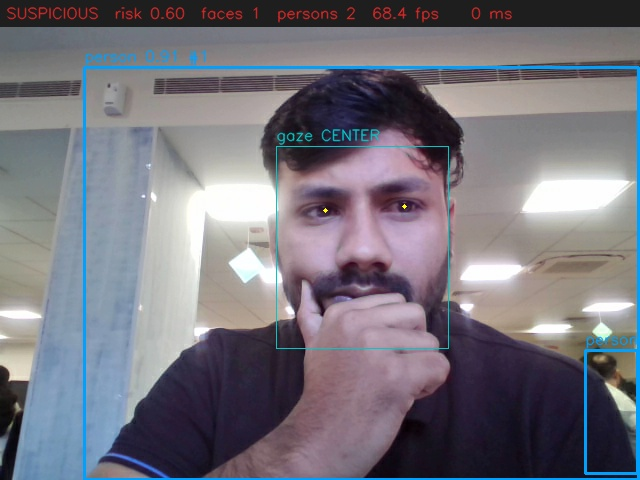

done: SUSPICIOUS | max risk 0.6 | events 4 | avg 8.6 ms/frame | output: d:\claude\interview\data\sessions\SESSION_20261012_104431


In [12]:
# --- webcam mode: runs for 60 s (interrupt the kernel to stop early; the summary is still written) ---
summary = run(0, max_seconds=60, display_mode="notebook")      # or display_mode="window" for a desktop window

## Plug in your XGBoost (optional)
`features_to_vector(features)` returns the model input in a fixed column order (`FEATURE_NAMES`, schema `FEATURE_SCHEMA_VERSION`).
Pass a function returning a score in [0, 1]; the notebook labels it `custom_model` instead of `rule_based_score`.
Only call it a probability if you trained **and calibrated** it on real labelled data.

In [ ]:
# import joblib
# model = joblib.load("models/xgboost_model/model.joblib")
# def my_risk(features, ongoing_events):
#     return float(model.predict_proba([features_to_vector(features)])[0, 1])
# summary = run("data/sample/test.mp4", risk_fn=my_risk)

ModuleNotFoundError: No module named 'joblib'